### Practicing Unsupervised Learning - Using Wine Dataset

In [6]:
## Import module/library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
## Load data -  Red Wine
df_raw_red = pd.read_csv("data/winequality-red.csv", sep=";")
df_raw_red.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [8]:
## Load data - White Wine
df_raw_white = pd.read_csv("winequality-white.csv", sep=";")
df_raw_white.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


### Data has no missing values for both categories
### We can do other EDA. Descriptive statistics, Histogram and KDE plots, etc

In [9]:
## Descriptive Statistics - All features are numerical
df_raw_red.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [10]:
## We rename the features using snake_case
df_raw_red.columns = df_raw_red.columns.str.replace(" ", "_")
df_raw_red.columns
df_raw_white.columns = df_raw_white.columns.str.replace(" ", "_")

In [11]:
red_cols = df_raw_red.columns
white_cols = df_raw_white.columns

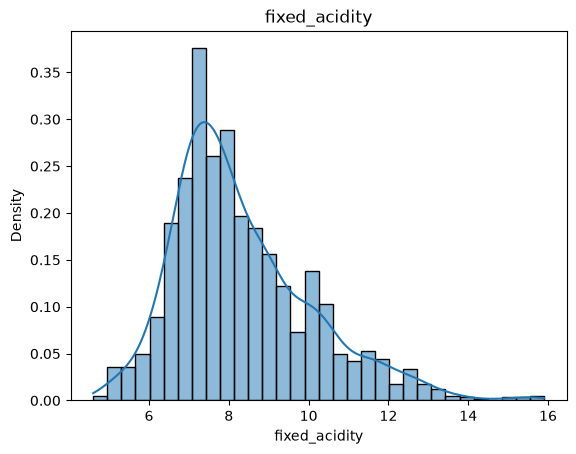

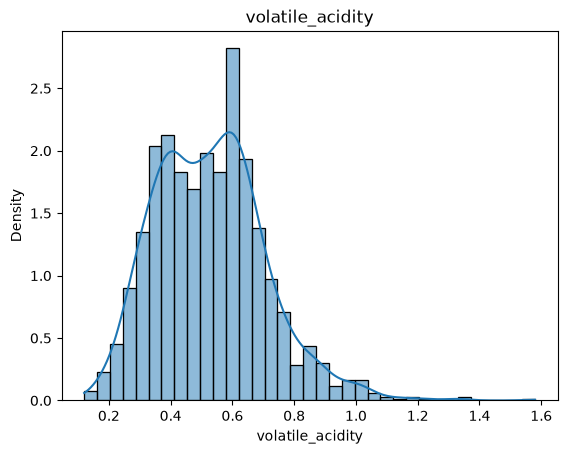

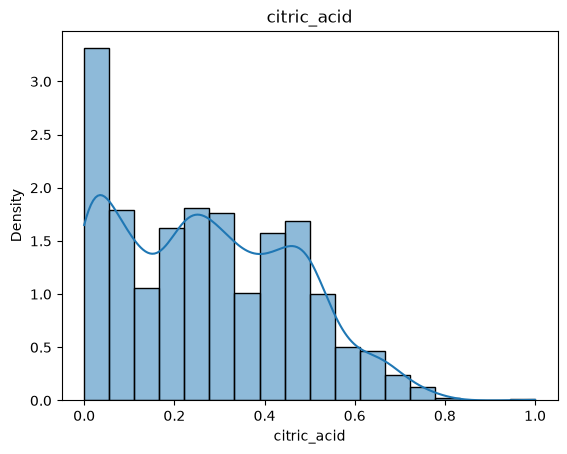

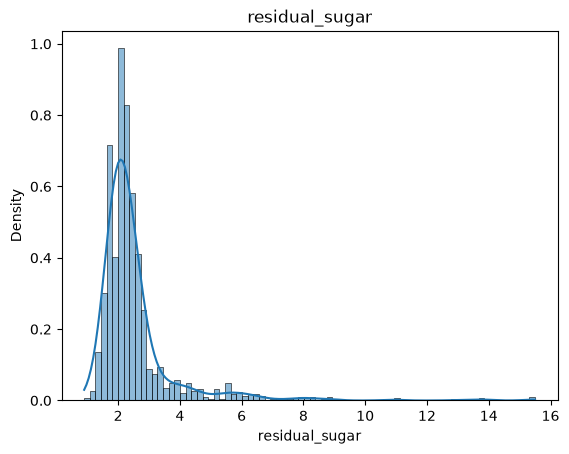

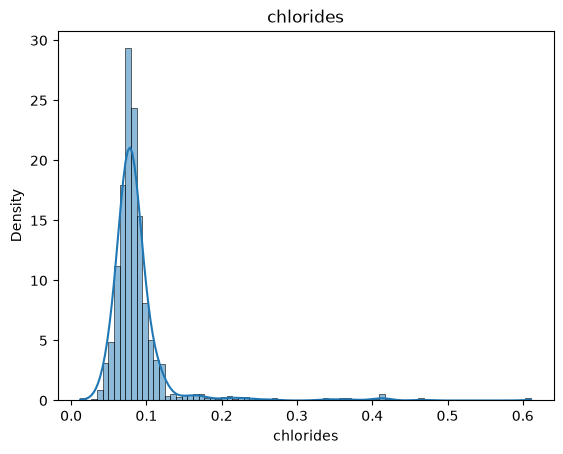

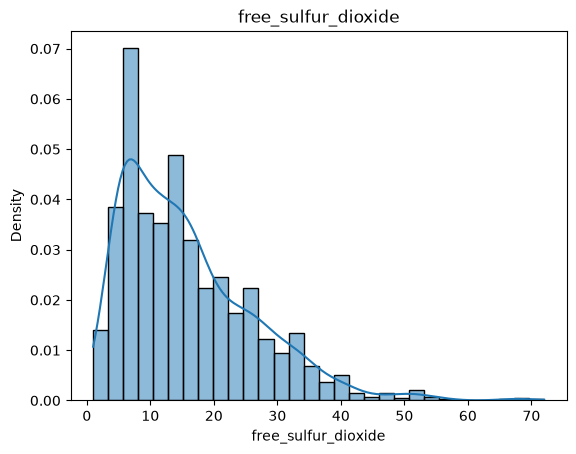

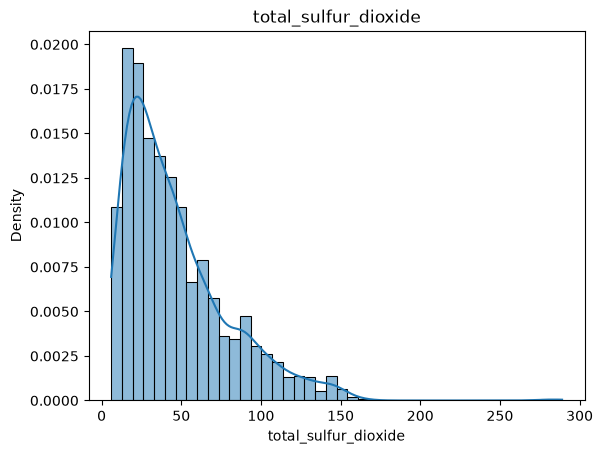

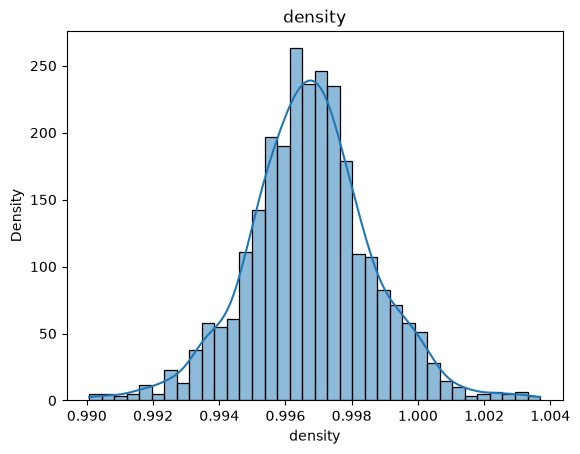

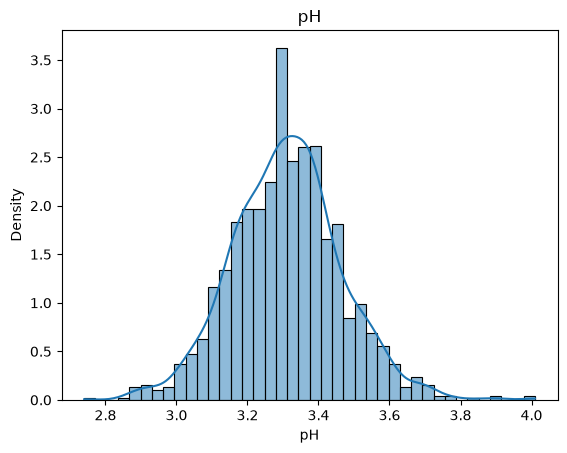

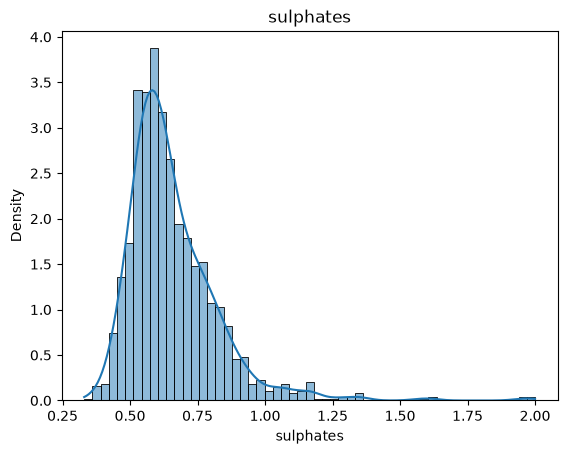

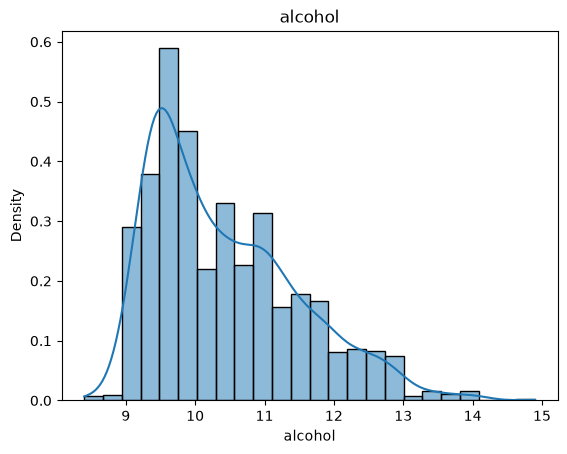

In [12]:
## We can try to plot the KDE (kernel density estimation) using Seaborn
for cols in red_cols[:-1]:
  sns.histplot(df_raw_red[cols], kde=True, stat="density")
  plt.title(cols)
  plt.show()

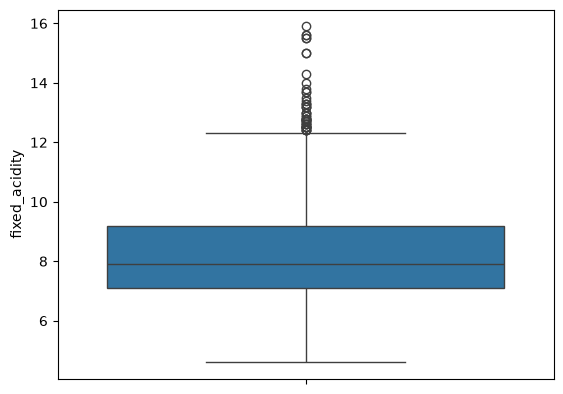

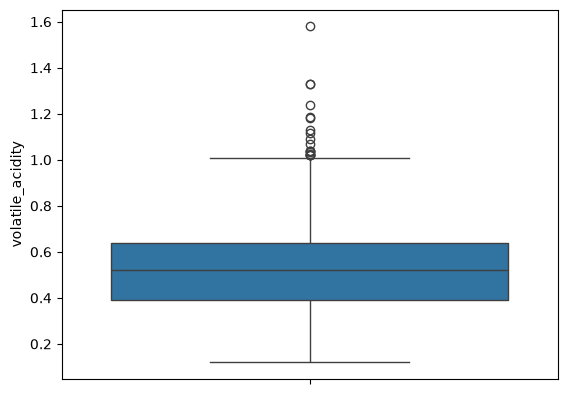

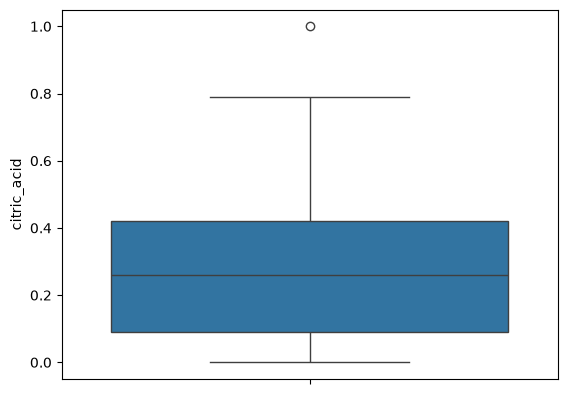

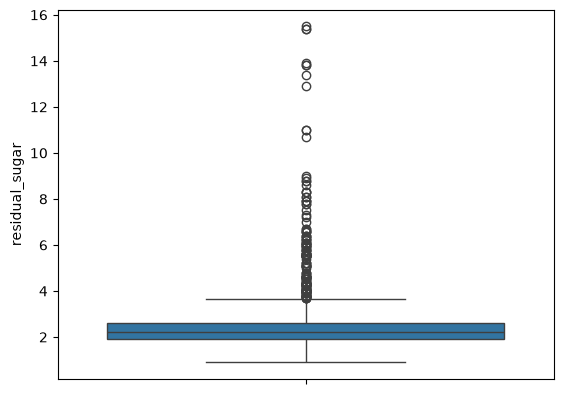

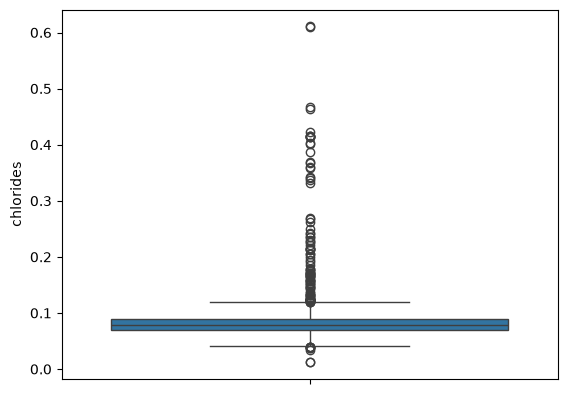

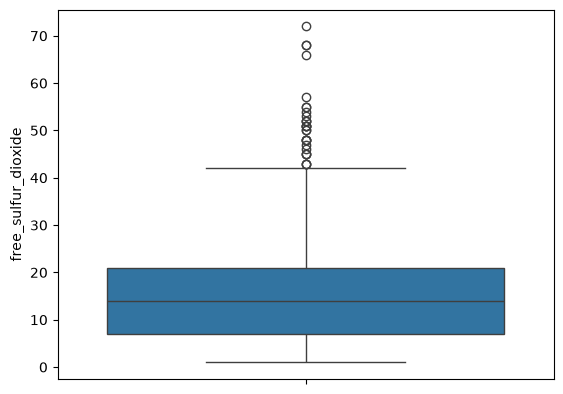

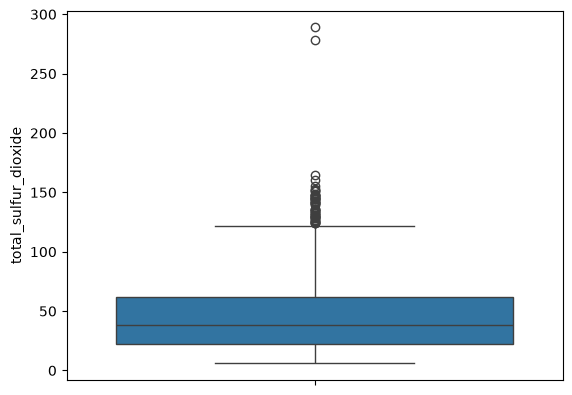

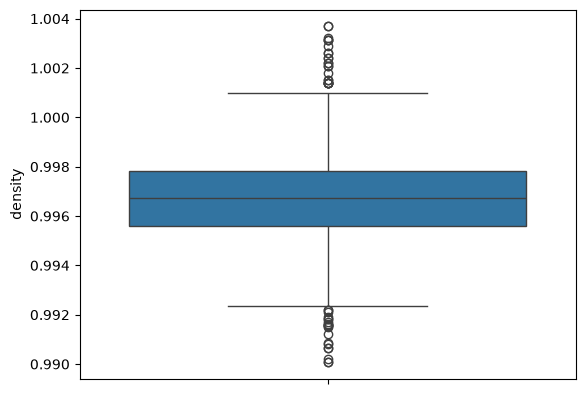

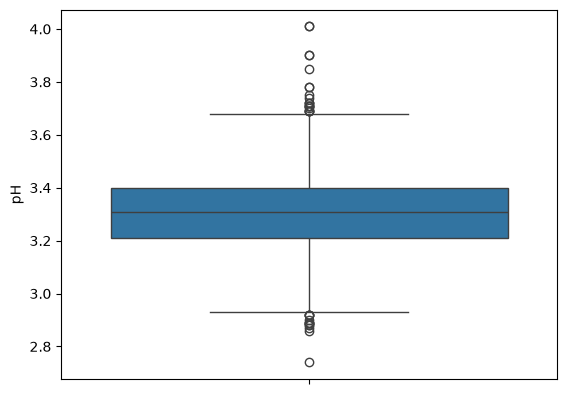

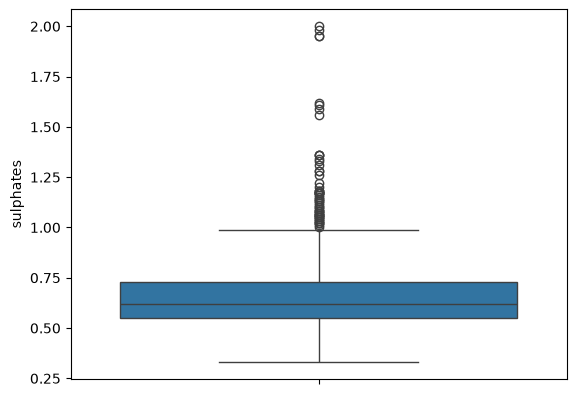

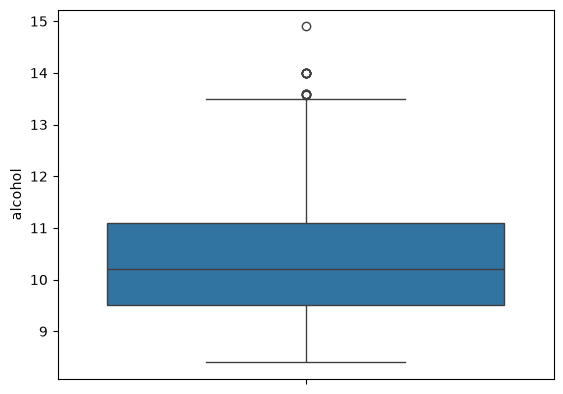

In [13]:
## Now we can observe for the outliers using boxplot
for cols in red_cols[:-1]:
  sns.boxplot(df_raw_red[cols])
  plt.show()

<Axes: >

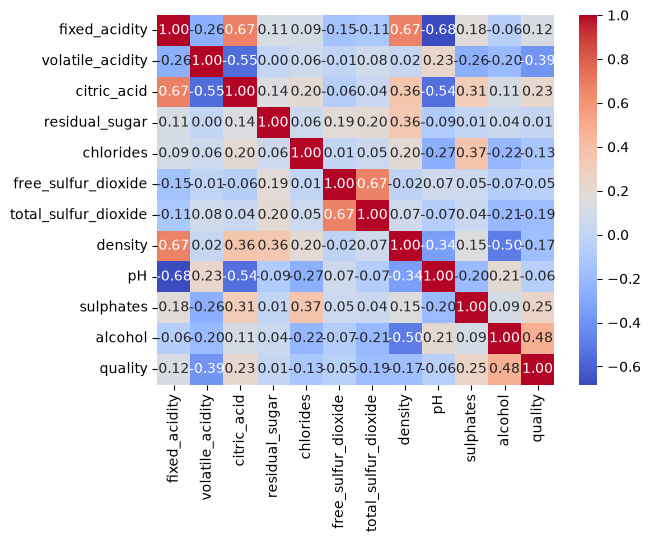

In [14]:
## Now we observe the correlation map between features - using Pearson Correlation Coefficients
pearson_corr = df_raw_red.corr(
  method="pearson"
)
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", fmt=".2f")

<Axes: >

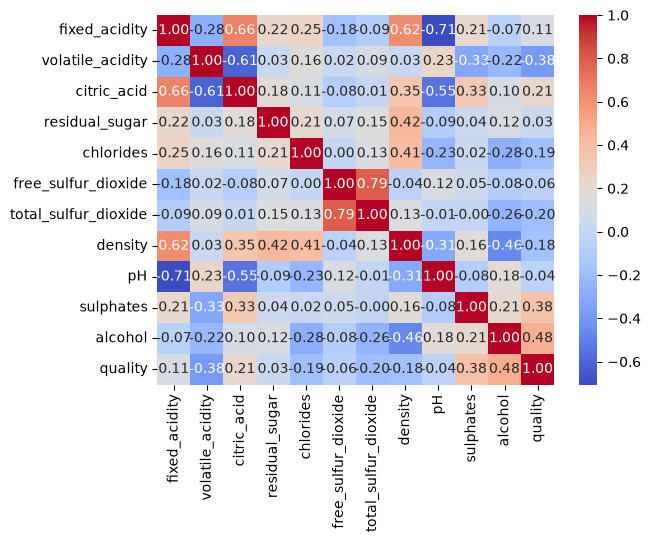

In [15]:
## We can also compare with other method, such as spearman
spearman_corr = df_raw_red.corr(
  method="spearman"
)
sns.heatmap(
  spearman_corr,
  annot=True,
  cmap="coolwarm",
  fmt=".2f"
)


### Observe scatter plots

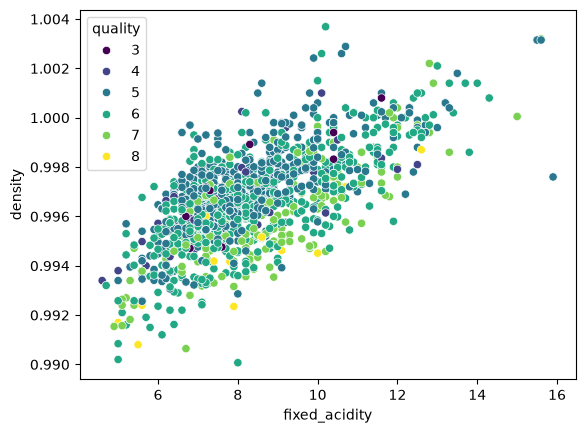

In [16]:
## We observe a few scatter plots - fixed_acidity v density (pearson: 0.67)
## It shows relatively linear
sns.scatterplot(x=df_raw_red['fixed_acidity'], y=df_raw_red['density'], data=df_raw_red, hue="quality", palette="viridis")
plt.show()

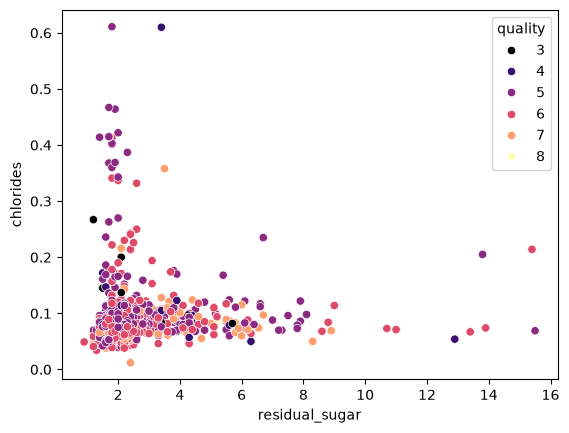

In [17]:
## Now we observe the less-correlated features - residual_sugar v chlorides
## The plots shows a little bit bottom-left centered
sns.scatterplot(
  x=df_raw_red['residual_sugar'],
  y=df_raw_red['chlorides'],
  data=df_raw_red,
  hue='quality',
  palette="magma"
)
plt.show()

In [18]:
## We can compare between pearson and spearman for both our scatterplots
pairs = [
  ('fixed_acidity', 'density'),
  ('residual_sugar', 'chlorides')
]

for x, y in pairs:
  pearson = df_raw_red[x].corr(df_raw_red[y], method="pearson")
  spearman = df_raw_red[x].corr(df_raw_red[y], method="spearman")

  print(f'{x} vs {y}')
  print(f'  pearson: {pearson: .2f}')
  print(f'  spearman: {spearman: .2f}')

fixed_acidity vs density
  pearson:  0.67
  spearman:  0.62
residual_sugar vs chlorides
  pearson:  0.06
  spearman:  0.21


### Observe pair plot

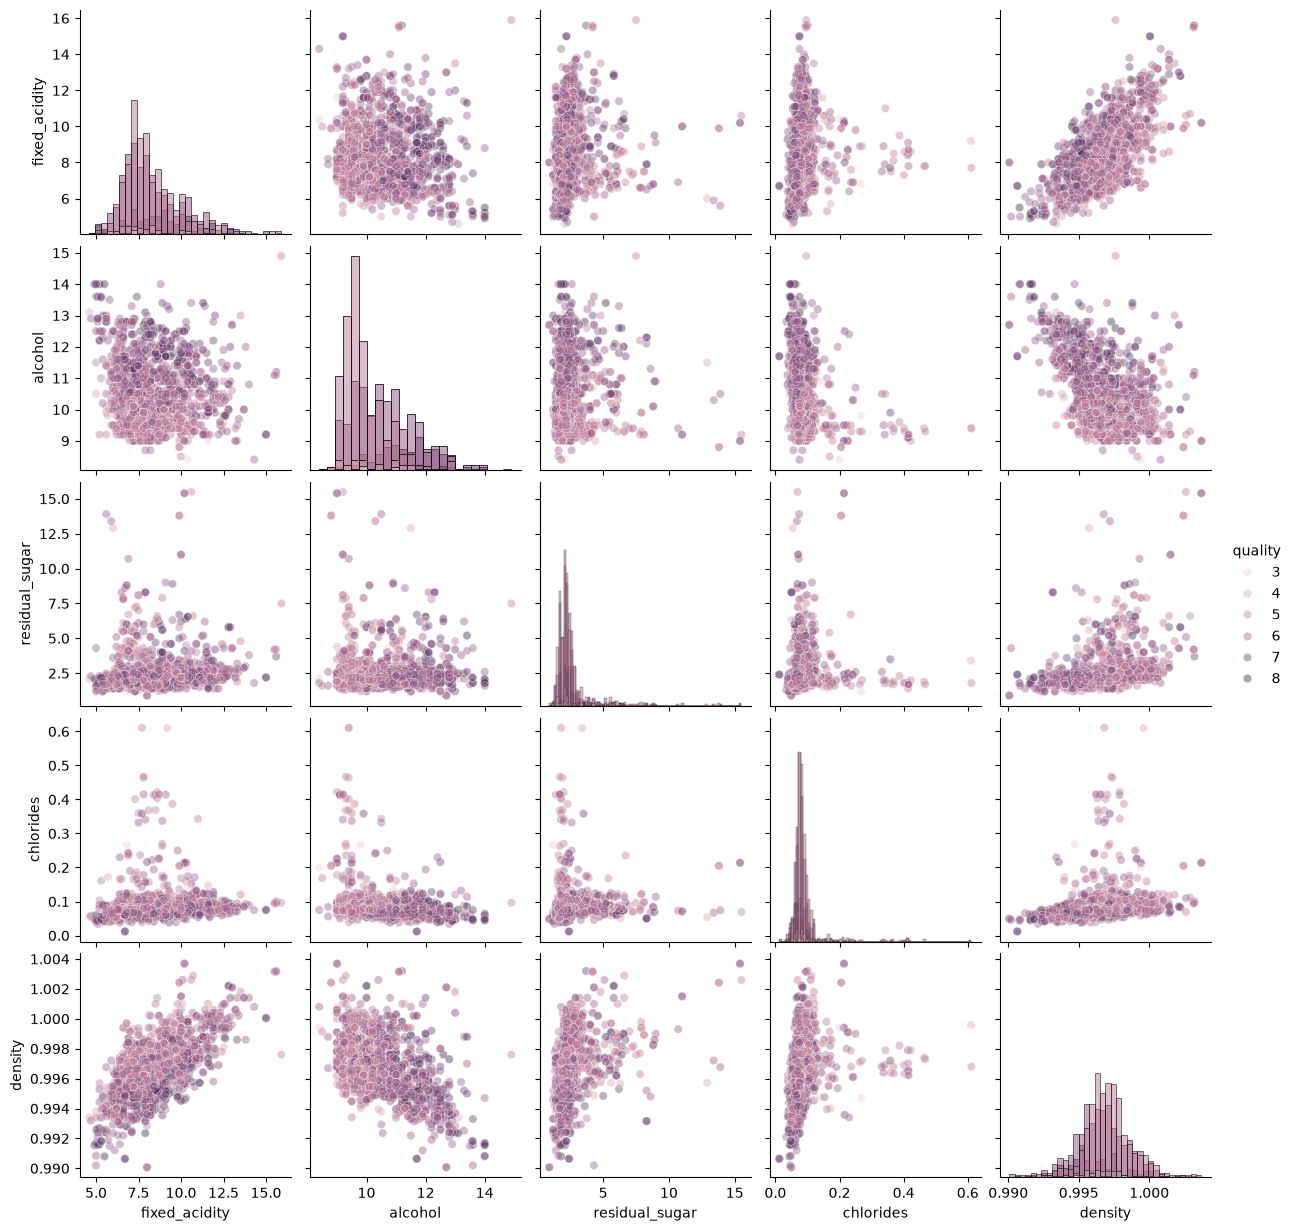

In [19]:
## We can observe multiple features here: alcohol, fixed_acidity, residual_sugar, chlorides and density
sns.pairplot(
  data=df_raw_red,
  vars=[
    'fixed_acidity',
    'alcohol',
    'residual_sugar',
    'chlorides',
    'density'
  ],
  hue='quality',
  diag_kind='hist',
  plot_kws={'alpha': 0.4}
)

### Feature Scaling

In [20]:
## Since we use numerical features and want to implement KMeans Clustering, it is crucial to scale the fatures.
## KMean calculate the distance between observation, so a larger range features can have more influence than others
## We will remove quality first, since we do clustering and use standard scaler
from sklearn.preprocessing import StandardScaler
X = df_raw_red.drop(columns=['quality'])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Dimensionality reduction - PCA (Principal Component Analysis)

In [21]:
## PCA transforms original features into a new set of features called Principal Components
from sklearn.decomposition import PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [22]:
## When we inspect the shape, it will be still the same, since we haven't reduced
print(f'X_scaled: {X_scaled.shape}')
print(f'PCA: {X_pca.shape}')

X_scaled: (1599, 11)
PCA: (1599, 11)


In [23]:
## Find the cumulative variance
print(np.cumsum(pca.explained_variance_ratio_))

[0.28173931 0.45682201 0.59778051 0.70807438 0.79528275 0.85524714
 0.90831906 0.94676967 0.97810077 0.99458561 1.        ]


In [24]:
## The rule of thumb of using PCA is to retain the smallest number of features while retaining the highest variance
## We can start with 2 features. In our case, it will retain ~46% of the variance
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

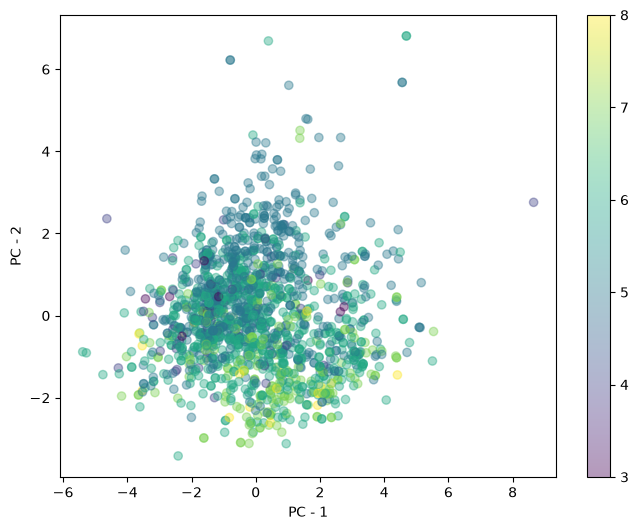

In [25]:
## Visualise - Looks like our scatter shows there aren't strong classification
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
  X_pca_2d[:,0],
  X_pca_2d[:,1],
  c=df_raw_red['quality'],
  cmap='viridis',
  alpha=0.4
)
plt.xlabel('PC - 1')
plt.ylabel('PC - 2')
plt.colorbar(scatter)
plt.show()

In [26]:
## Check the variance, if it agrees with the calculation (~46%)
print(f'Variance: {pca_2d.explained_variance_ratio_.sum():.2%}')

Variance: 45.68%


### Prepare data for clustering

In [27]:
## Now we can use the KMeans to see group - We start to divide into 3 groups and we can play around later
## n_init = Runs KMeans 10 times with different initial starting points
from sklearn.cluster import KMeans
kmeans = KMeans(
  n_clusters=3,
  random_state=42,
  n_init=10
)

In [28]:
## Fit the data
kmeans.fit(X_scaled)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 11)","[[-0

In [29]:
labels = kmeans.labels_
pd.Series(labels).value_counts().sort_index()

0    722
1    502
2    375
Name: count, dtype: int64

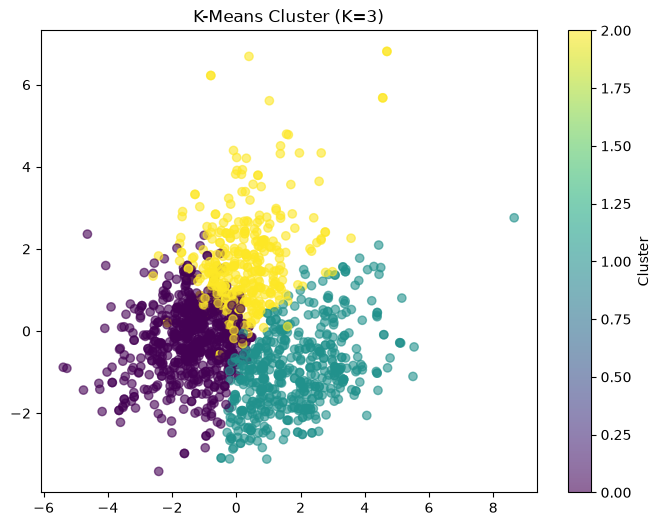

In [30]:
## Visualise
plt.figure(figsize=(8, 6))
plt.scatter(
  X_pca_2d[:,0],
  X_pca_2d[:,1],
  c=labels,
  cmap='viridis',
  alpha=0.6
)
plt.colorbar(label='Cluster')
plt.title('K-Means Cluster (K=3)')
plt.show()

In [31]:
## Evaluate cluster with silhouette score - Silhouette score tells us that the clusters are overlapping. There's features which should
## be on another cluster
from sklearn.metrics import silhouette_score
score = silhouette_score(X_scaled, labels)
print(f'Silhouette score: {score:.2f}')

Silhouette score: 0.19


In [32]:
## Find the optimum K number
inertia = []
for k in range(1, 11):
  kmeans = KMeans(
    n_clusters=k,
    random_state=10,
    n_init=10
  )
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

print(inertia)

[17589.000000000004, 14330.144113132046, 12630.042737029662, 11459.157149646384, 10155.92055217512, 9361.147121278958, 8645.745950920453, 8305.132682210051, 7968.235846847945, 7675.2823141808185]


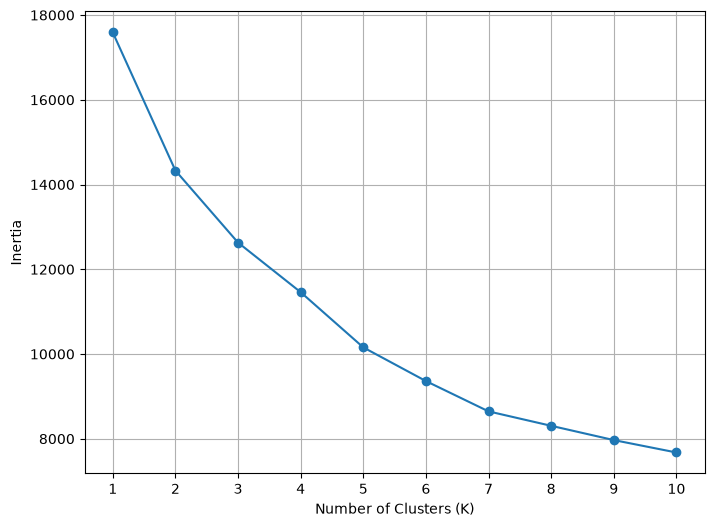

In [33]:
## Now, we visualise the inertia - Elbow method
plt.figure(figsize=(8, 6))
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [34]:
## We can now evaluate the cluster from 2 to 8 with the silhouette score
silhouette_scores = []
for k in range(2, 9):
  kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
  )
  labels_k = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, labels_k)
  silhouette_scores.append(score)
  print(f'K = {k}, Silhouette Score: {score:.3f}')

K = 2, Silhouette Score: 0.214
K = 3, Silhouette Score: 0.189
K = 4, Silhouette Score: 0.172
K = 5, Silhouette Score: 0.190
K = 6, Silhouette Score: 0.195
K = 7, Silhouette Score: 0.193
K = 8, Silhouette Score: 0.150


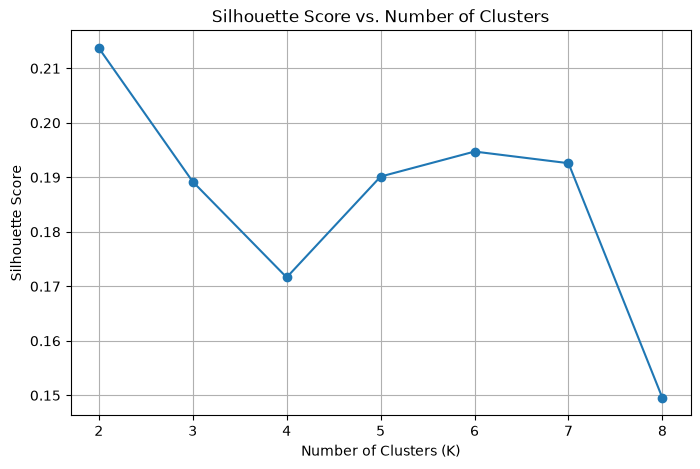

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(range(2, 9), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score vs. Number of Clusters')
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [36]:
## Use KMeans with 2 Clusters
from sklearn.cluster import KMeans

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_2 = kmeans_2.fit_predict(X_scaled)

df_clusters = df_raw_red.copy()
df_clusters['cluster'] = labels_2

In [37]:
cluster_means = df_clusters.groupby('cluster').mean(numeric_only=True).T
print(cluster_means.round(2))

cluster                   0      1
fixed_acidity          9.92   7.38
volatile_acidity       0.41   0.59
citric_acid            0.46   0.16
residual_sugar         2.77   2.41
chlorides              0.10   0.08
free_sulfur_dioxide   13.41  17.32
total_sulfur_dioxide  39.39  50.61
density                1.00   1.00
pH                     3.20   3.38
sulphates              0.75   0.61
alcohol               10.61  10.32
quality                5.89   5.48


In [38]:
print(df_clusters['cluster'].value_counts().sort_index())

cluster
0     590
1    1009
Name: count, dtype: int64


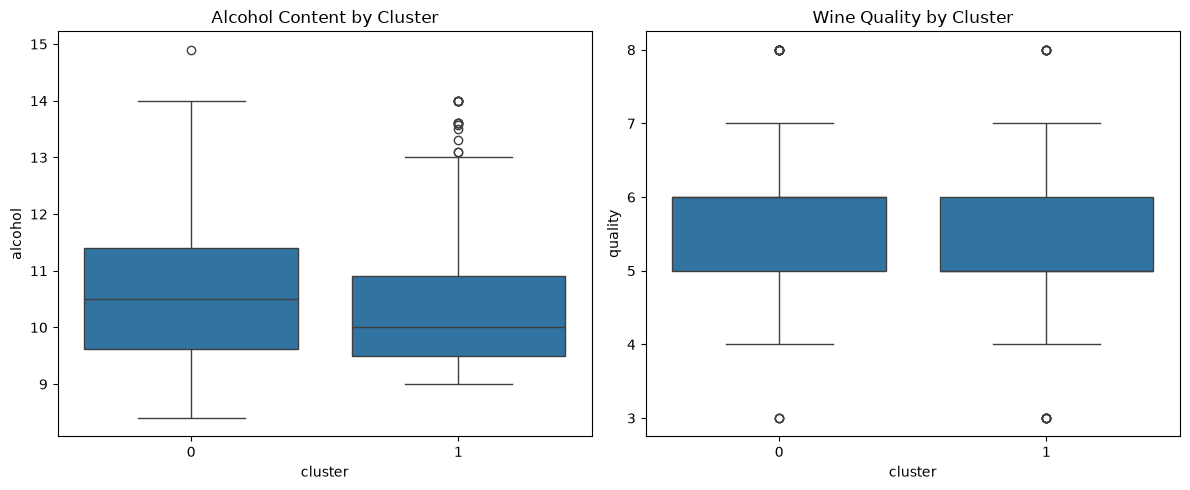

In [39]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df_clusters, x='cluster', y='alcohol', ax=axes[0])
axes[0].set_title('Alcohol Content by Cluster')

sns.boxplot(data=df_clusters, x='cluster', y='quality', ax=axes[1])
axes[1].set_title('Wine Quality by Cluster')

plt.tight_layout()
plt.show()

### We can try to observe the PCA with 4 features - The reason being, the improvement of variance from 4 to 5 relatively
### in the in the middle compared to other values

In [45]:
pca_4d = PCA(n_components=4)
X_pca_4d = pca_4d.fit_transform(X_scaled)

In [47]:
## We observe the variance
print(f"Variance per component: {pca_4d.explained_variance_ratio_.round(4)}")

print(f"Total variance explained: {pca_4d.explained_variance_ratio_.sum()}")

Variance per component: [0.2817 0.1751 0.141  0.1103]
Total variance explained: 0.7080743772386735


In [48]:
## We already observed the silhouette score with different Ks but we used all the 11 features. Now, we also observed
## the solhouette score using only 4 features with also different Ks, start with 2
kmeans_pca4 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels_pca4 = kmeans_pca4.fit_predict(X_pca_4d)
score_pca4 = silhouette_score(X_pca_4d, labels_pca4)

print(f"Silhouette score (4 PCAs): {score_pca4:.3f}")

Silhouette score (4 PCAs): 0.292


In [49]:
## We can do the similar approach as before, where we compare different score for different Ks
silhouette_scores_pca4d = []

for k in range(2, 10):
  pca = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
  )
  labels = pca.fit_predict(X_pca_4d)
  score = silhouette_score(X_pca_4d, labels)
  silhouette_scores_pca4d.append(score)
  print(f"Silhoutte score K ({k}): {score}")

Silhoutte score K (2): 0.29181464361983933
Silhoutte score K (3): 0.26946800847307206
Silhoutte score K (4): 0.29208796725255665
Silhoutte score K (5): 0.29503384950316974
Silhoutte score K (6): 0.2917303263792473
Silhoutte score K (7): 0.2700545217086945
Silhoutte score K (8): 0.24874780611114936
Silhoutte score K (9): 0.23064129137576372


In [51]:
## We can also observe for a different PCAs and observe the silhouette scores and variance retained
for n in range (2, 12):
  pca = PCA(n_components=n)
  X_pca = pca.fit_transform(X_scaled)

  ## Then we use 2 clusters for every PCA
  kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
  )
  labels = kmeans.fit_predict(X_pca)
  score = silhouette_score(X_scaled, labels)

  variance = pca.explained_variance_ratio_.sum().round(3)

  print(
    f"Components: {n} | "
    f"Variance retained: {variance} | "
    f"Silhouette score: {score:.3f}"
  )


Components: 2 | Variance retained: 0.457 | Silhouette score: 0.212
Components: 3 | Variance retained: 0.598 | Silhouette score: 0.213
Components: 4 | Variance retained: 0.708 | Silhouette score: 0.213
Components: 5 | Variance retained: 0.795 | Silhouette score: 0.214
Components: 6 | Variance retained: 0.855 | Silhouette score: 0.214
Components: 7 | Variance retained: 0.908 | Silhouette score: 0.213
Components: 8 | Variance retained: 0.947 | Silhouette score: 0.214
Components: 9 | Variance retained: 0.978 | Silhouette score: 0.214
Components: 10 | Variance retained: 0.995 | Silhouette score: 0.214
Components: 11 | Variance retained: 1.0 | Silhouette score: 0.214
